In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("used_device_data.csv")


print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())


Dataset loaded successfully!
Number of rows: 5454
Number of columns: 24


,device_brand,os,screen_size,4g,5g,rear_camera_mp,front_camera_mp,internal_memory,ram,battery,...,normalized_new_price,record_origin,added_feature_source,model_name,battery_health_pct,physical_condition,warranty_remaining_months,has_original_box,has_original_charger,screen_condition
0,Honor,Android,14.50,yes,no,13.0,5.0,64.0,3.0,3020.0,...,4.715100,Original dataset,Estimated enrichment; not present in source,Honor legacy model (unspecified),62,Poor,0,yes,yes,Excellent
1,Honor,Android,17.30,yes,yes,13.0,16.0,128.0,8.0,4300.0,...,5.519018,Original dataset,Estimated enrichment; not present in source,Honor legacy model (unspecified),74,Fair,0,no,yes,Minor scratches
2,Honor,Android,16.69,yes,yes,13.0,8.0,128.0,8.0,4200.0,...,5.884631,Original dataset,Estimated enrichment; not present in source,Honor legacy model (unspecified),74,Fair,0,no,yes,Good
3,Honor,Android,25.50,yes,yes,13.0,8.0,64.0,6.0,7250.0,...,5.630961,Original dataset,Estimated enrichment; not present in source,Honor legacy model (unspecified),69,Poor,0,yes,yes,Excellent
4,Honor,Android,15.32,yes,no,13.0,8.0,64.0,3.0,5000.0,...,4.947837,Original dataset,Estimated enrichment; not present in source,Honor legacy model (unspecified),63,Poor,0,no,yes,Good


In [3]:

print("COLUMN NAMES")
print(df.columns.tolist())

print("\nDATA TYPES AND NON-NULL COUNTS")
df.info()

print("\nMISSING VALUES")
display(df.isnull().sum().sort_values(ascending=False))

print("\nDUPLICATE ROWS:", df.duplicated().sum())


COLUMN NAMES
['device_brand', 'os', 'screen_size', '4g', '5g', 'rear_camera_mp', 'front_camera_mp', 'internal_memory', 'ram', 'battery', 'weight', 'release_year', 'days_used', 'normalized_used_price', 'normalized_new_price', 'record_origin', 'added_feature_source', 'model_name', 'battery_health_pct', 'physical_condition', 'warranty_remaining_months', 'has_original_box', 'has_original_charger', 'screen_condition']

DATA TYPES AND NON-NULL COUNTS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5454 entries, 0 to 5453
Data columns (total 24 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   device_brand               5454 non-null   object 
 1   os                         5454 non-null   object 
 2   screen_size                5454 non-null   float64
 3   4g                         5454 non-null   object 
 4   5g                         5454 non-null   object 
 5   rear_camera_mp             5275 non-null   floa

,0
rear_camera_mp,179
weight,7
battery,6
internal_memory,4
ram,4
front_camera_mp,2
4g,0
device_brand,0
5g,0
os,0



DUPLICATE ROWS: 0


NUMERICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
screen_size,5454.0,11.058597,4.622594,5.080000,6.680000,10.340000,12.900000,30.7100
rear_camera_mp,5275.0,25.650726,27.541011,0.080000,8.000000,13.000000,49.000000,201.2000
front_camera_mp,5452.0,12.768929,12.734624,0.000000,2.100000,8.000000,16.000000,51.8000
internal_memory,5450.0,131.920218,166.375813,0.010000,32.000000,64.000000,256.000000,1024.0000
ram,5450.0,5.979196,3.245136,0.020000,4.000000,4.000000,8.000000,16.0000
battery,5448.0,3671.773036,1333.512671,500.000000,2600.000000,3600.000000,4738.250000,9720.0000
weight,5447.0,184.918983,70.912448,69.000000,152.000000,174.000000,195.000000,855.0000
release_year,5454.0,2018.726439,4.102122,2013.000000,2015.000000,2018.000000,2023.000000,2025.0000
days_used,5454.0,638.975798,304.530611,15.000000,407.000000,653.500000,856.000000,1885.0000
normalized_used_price,5454.0,4.541965,0.936138,1.500000,4.033754,4.487781,4.978762,7.7568


Release year range: 2013 to 2025


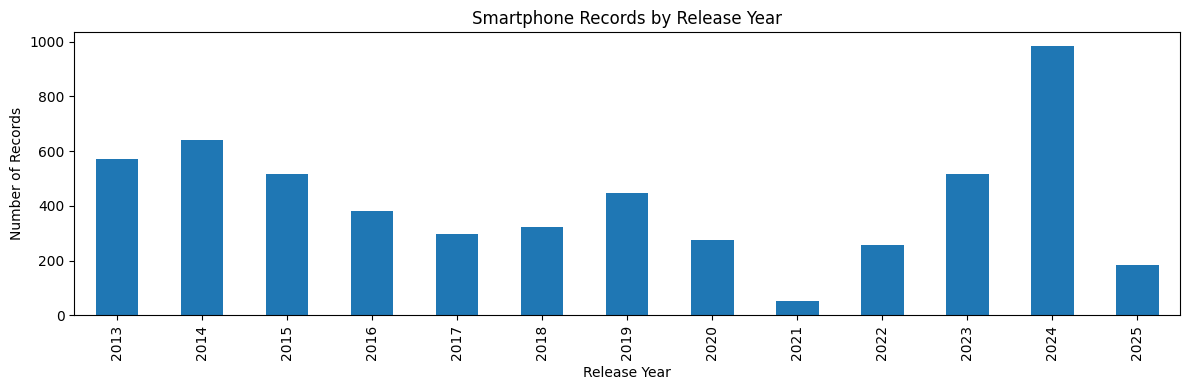

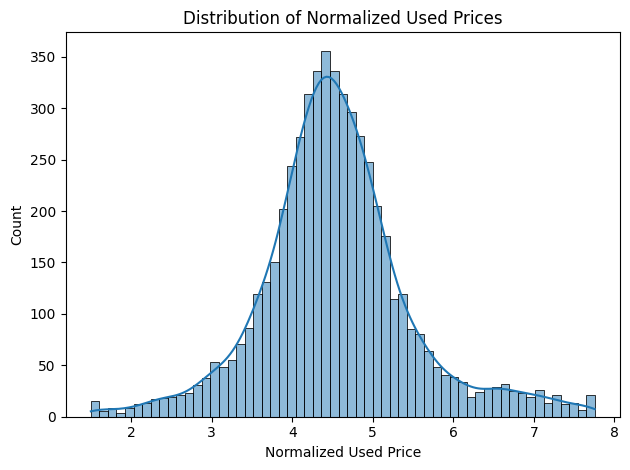

In [4]:

print("NUMERICAL SUMMARY")
display(df.describe().T)

if "release_year" in df.columns:
    print("Release year range:",
          df["release_year"].min(),
          "to",
          df["release_year"].max())

    df["release_year"].value_counts().sort_index().plot(
        kind="bar", figsize=(12, 4)
    )
    plt.title("Smartphone Records by Release Year")
    plt.xlabel("Release Year")
    plt.ylabel("Number of Records")
    plt.tight_layout()
    plt.show()

target = "normalized_used_price"

if target in df.columns:
    sns.histplot(df[target].dropna(), kde=True)
    plt.title("Distribution of Normalized Used Prices")
    plt.xlabel("Normalized Used Price")
    plt.tight_layout()
    plt.show()
else:
    print("Target column not found. Check the printed column names.")


# Exploratory Data Analysis

In [5]:

display(df.describe().T.round(2))

categorical_cols = df.select_dtypes(include="object").columns

for col in categorical_cols:
    print(f"\n{col}: {df[col].nunique()} unique values")
    print(df[col].value_counts().head(10))


,count,mean,std,min,25%,50%,75%,max
screen_size,5454.0,11.06,4.62,5.08,6.68,10.34,12.90,30.71
rear_camera_mp,5275.0,25.65,27.54,0.08,8.00,13.00,49.00,201.20
front_camera_mp,5452.0,12.77,12.73,0.00,2.10,8.00,16.00,51.80
internal_memory,5450.0,131.92,166.38,0.01,32.00,64.00,256.00,1024.00
ram,5450.0,5.98,3.25,0.02,4.00,4.00,8.00,16.00
battery,5448.0,3671.77,1333.51,500.00,2600.00,3600.00,4738.25,9720.00
weight,5447.0,184.92,70.91,69.00,152.00,174.00,195.00,855.00
release_year,5454.0,2018.73,4.10,2013.00,2015.00,2018.00,2023.00,2025.00
days_used,5454.0,638.98,304.53,15.00,407.00,653.50,856.00,1885.00
normalized_used_price,5454.0,4.54,0.94,1.50,4.03,4.49,4.98,7.76



device_brand: 36 unique values
device_brand
Samsung    678
Others     502
Apple      396
Xiaomi     386
Huawei     251
Oppo       249
Vivo       233
OnePlus    228
Google     228
LG         201
Name: count, dtype: int64

os: 4 unique values
os
Android    4857
iOS         393
Others      137
Windows      67
Name: count, dtype: int64

4g: 2 unique values
4g
yes    4335
no     1119
Name: count, dtype: int64

5g: 2 unique values
5g
no     3302
yes    2152
Name: count, dtype: int64

record_origin: 2 unique values
record_origin
Original dataset                 3454
Synthetic modern-model record    2000
Name: count, dtype: int64

added_feature_source: 2 unique values
added_feature_source
Estimated enrichment; not present in source       3454
Synthetic; generated for educational modelling    2000
Name: count, dtype: int64

model_name: 68 unique values
model_name
Others legacy model (unspecified)     502
Samsung legacy model (unspecified)    341
Huawei legacy model (unspecified)     251
LG leg

In [6]:

print("Record origin:")
display(df["record_origin"].value_counts())

print("\nAdded feature source:")
display(df["added_feature_source"].value_counts())

print("\nRelease year range:")
print(df["release_year"].min(), "-", df["release_year"].max())

print("\nRecords by release year:")
display(df["release_year"].value_counts().sort_index())


Record origin:


,count
record_origin,
Original dataset,3454
Synthetic modern-model record,2000



Added feature source:


,count
added_feature_source,
Estimated enrichment; not present in source,3454
Synthetic; generated for educational modelling,2000



Release year range:
2013 - 2025

Records by release year:


,count
release_year,
2013,570
2014,642
2015,515
2016,383
2017,299
2018,322
2019,446
2020,277
2021,53


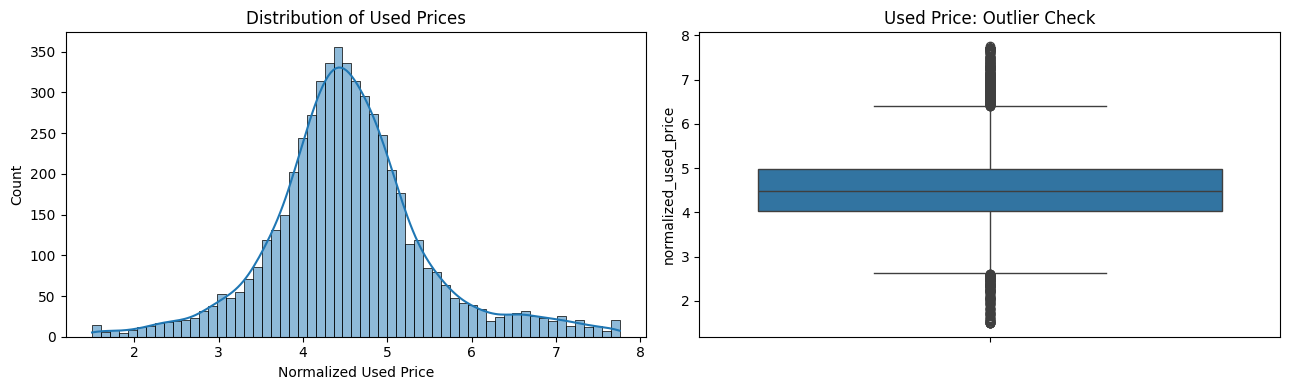

In [7]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    data=df,
    x="normalized_used_price",
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribution of Used Prices")
axes[0].set_xlabel("Normalized Used Price")

sns.boxplot(
    data=df,
    y="normalized_used_price",
    ax=axes[1]
)
axes[1].set_title("Used Price: Outlier Check")

plt.tight_layout()
plt.show()


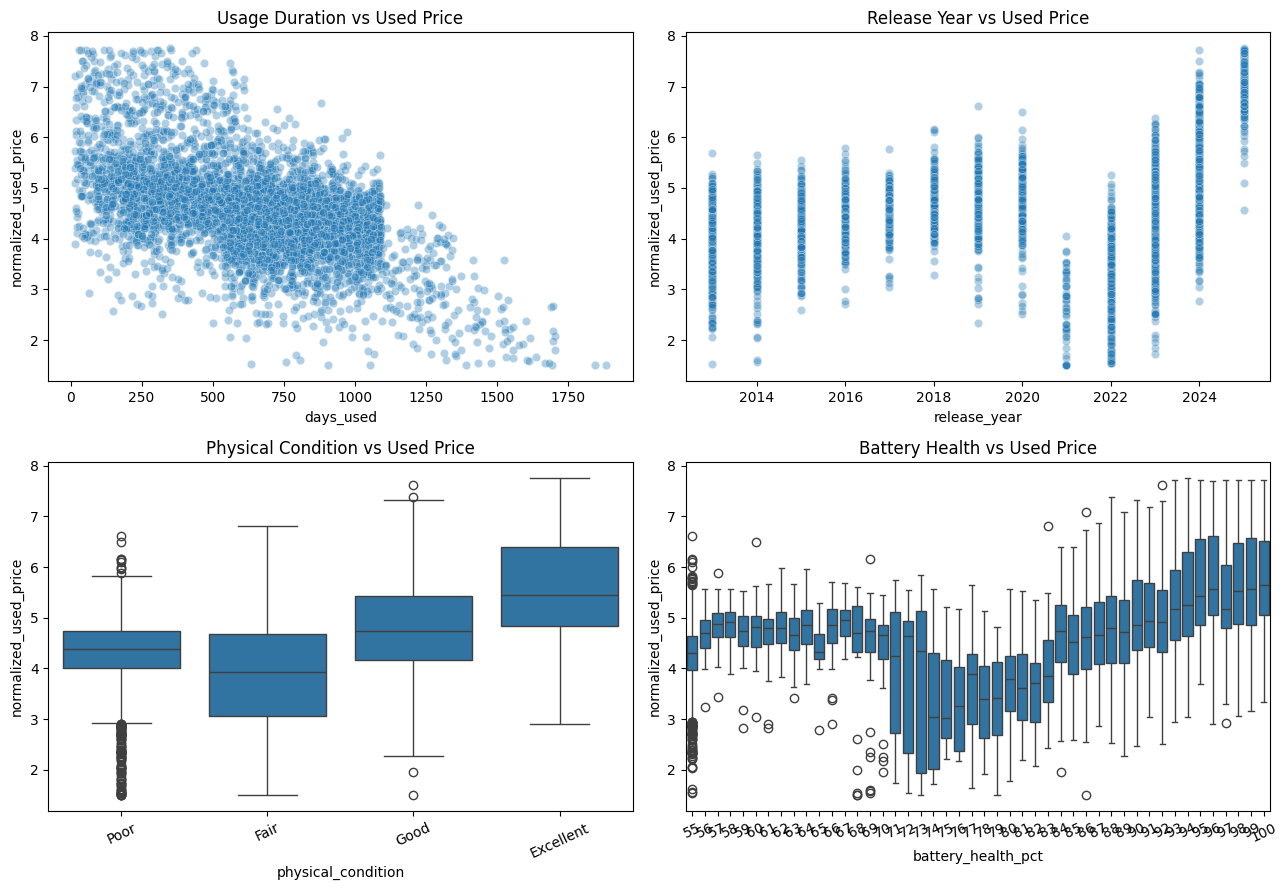

In [8]:

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.scatterplot(
    data=df, x="days_used", y="normalized_used_price",
    alpha=0.35, ax=axes[0, 0]
)
axes[0, 0].set_title("Usage Duration vs Used Price")

sns.scatterplot(
    data=df, x="release_year", y="normalized_used_price",
    alpha=0.35, ax=axes[0, 1]
)
axes[0, 1].set_title("Release Year vs Used Price")

sns.boxplot(
    data=df, x="physical_condition",
    y="normalized_used_price", ax=axes[1, 0]
)
axes[1, 0].set_title("Physical Condition vs Used Price")
axes[1, 0].tick_params(axis="x", rotation=25)

sns.boxplot(
    data=df, x="battery_health_pct",
    y="normalized_used_price", ax=axes[1, 1]
)
axes[1, 1].set_title("Battery Health vs Used Price")
axes[1, 1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

# Preparing the data for machine learning

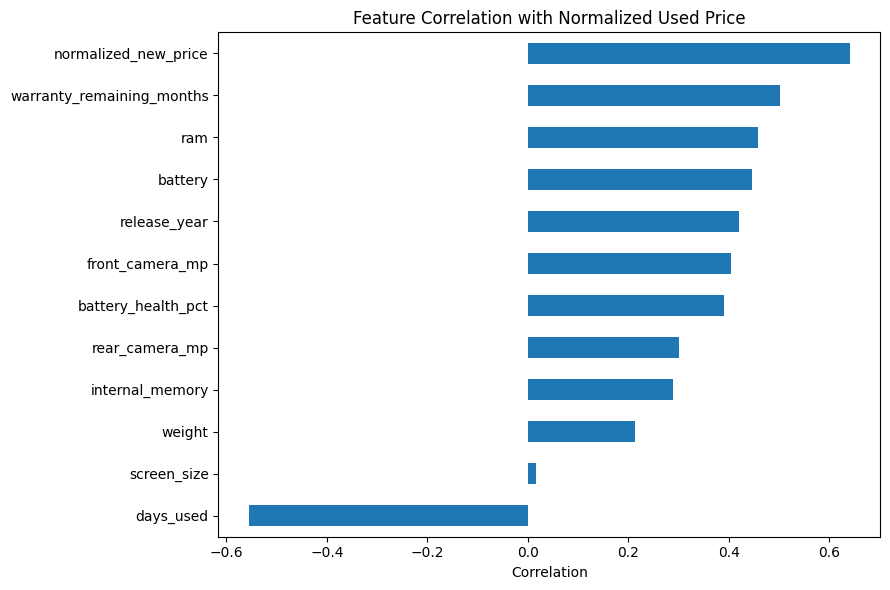

,Correlation with used price
days_used,-0.555859
screen_size,0.016999
weight,0.213317
internal_memory,0.288760
rear_camera_mp,0.301250
battery_health_pct,0.390511
front_camera_mp,0.404063
release_year,0.420519
battery,0.445264
ram,0.457265


In [9]:

numeric_cols = df.select_dtypes(include=np.number).columns

correlations = (
    df[numeric_cols]
    .corr()["normalized_used_price"]
    .drop("normalized_used_price")
    .sort_values()
)

plt.figure(figsize=(9, 6))
correlations.plot(kind="barh")
plt.title("Feature Correlation with Normalized Used Price")
plt.xlabel("Correlation")
plt.tight_layout()
plt.show()

display(correlations.to_frame("Correlation with used price"))

In [10]:

target = "normalized_used_price"

drop_cols = [
    target,
    "record_origin",
    "added_feature_source",
    "model_name"
]

X = df.drop(columns=drop_cols)
y = df[target].copy()

print("Feature matrix:", X.shape)
print("Target:", y.shape)

print("\nNumeric features:")
print(X.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical features:")
print(X.select_dtypes(include="object").columns.tolist())

Feature matrix: (5454, 20)
Target: (5454,)

Numeric features:
['screen_size', 'rear_camera_mp', 'front_camera_mp', 'internal_memory', 'ram', 'battery', 'weight', 'release_year', 'days_used', 'normalized_new_price', 'battery_health_pct', 'warranty_remaining_months']

Categorical features:
['device_brand', 'os', '4g', '5g', 'physical_condition', 'has_original_box', 'has_original_charger', 'screen_condition']


In [11]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 4363
Testing records: 1091


In [12]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include="object"
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline configured.")
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))


Preprocessing pipeline configured.
Numeric features: 12
Categorical features: 8


# Train and compare the models

In [13]:

from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import time

In [14]:

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.01, max_iter=10000),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=12,
        min_samples_leaf=5,
        random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=150,
        max_depth=18,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}
results = []

for name, model in models.items():
    print(f"Training {name}...")
    start = time.time()

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    trained_models[name] = pipeline

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2,
        "Training Time (s)": round(time.time() - start, 2)
    })

results_df = pd.DataFrame(results).sort_values("RMSE")
display(results_df.round(4))


Training Linear Regression...
Training Ridge Regression...
Training Lasso Regression...
Training Decision Tree...
Training Random Forest...


,Model,MAE,RMSE,R2 Score,Training Time (s)
4,Random Forest,0.2288,0.3011,0.9036,5.06
3,Decision Tree,0.2716,0.3720,0.8527,0.09
0,Linear Regression,0.3160,0.4227,0.8099,0.15
1,Ridge Regression,0.3160,0.4230,0.8096,0.08
2,Lasso Regression,0.3407,0.4731,0.7619,0.09


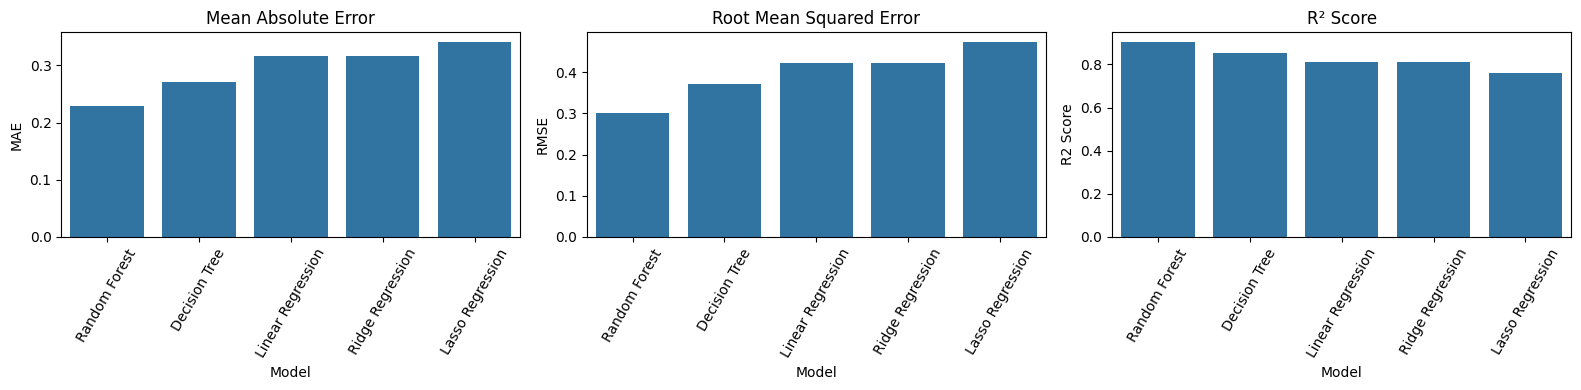

In [15]:

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.barplot(data=results_df, x="Model", y="MAE", ax=axes[0])
axes[0].set_title("Mean Absolute Error")
axes[0].tick_params(axis="x", rotation=60)

sns.barplot(data=results_df, x="Model", y="RMSE", ax=axes[1])
axes[1].set_title("Root Mean Squared Error")
axes[1].tick_params(axis="x", rotation=60)

sns.barplot(data=results_df, x="Model", y="R2 Score", ax=axes[2])
axes[2].set_title("R² Score")
axes[2].tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

Best model by test RMSE: Random Forest


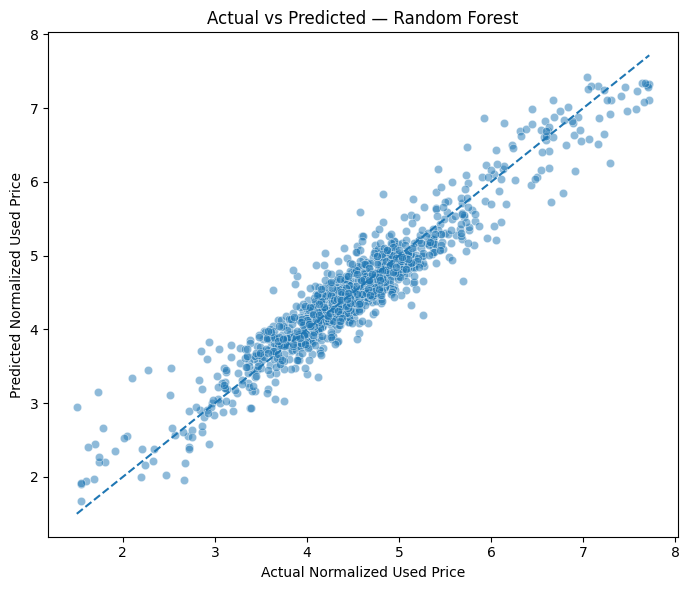

In [16]:

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
best_predictions = best_model.predict(X_test)

print("Best model by test RMSE:", best_model_name)

plt.figure(figsize=(7, 6))
sns.scatterplot(x=y_test, y=best_predictions, alpha=0.5)

lower = min(y_test.min(), best_predictions.min())
upper = max(y_test.max(), best_predictions.max())

plt.plot([lower, upper], [lower, upper], linestyle="--")
plt.xlabel("Actual Normalized Used Price")
plt.ylabel("Predicted Normalized Used Price")
plt.title(f"Actual vs Predicted — {best_model_name}")
plt.tight_layout()
plt.show()

# Hyperparameter tuning with GridSearchCV

In [17]:
from sklearn.model_selection import GridSearchCV

rf_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [10, 18, None],
    "model__min_samples_leaf": [1, 3]
}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=3,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation RMSE:")
print(-grid_search.best_score_)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters:
{'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}

Best cross-validation RMSE:
0.3130663079386962


In [18]:

best_rf = grid_search.best_estimator_
tuned_predictions = best_rf.predict(X_test)

tuned_results = {
    "Model": "Tuned Random Forest",
    "MAE": mean_absolute_error(y_test, tuned_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, tuned_predictions)),
    "R2 Score": r2_score(y_test, tuned_predictions)
}

comparison = pd.concat([
    results_df[["Model", "MAE", "RMSE", "R2 Score"]],
    pd.DataFrame([tuned_results])
], ignore_index=True)

comparison = comparison.sort_values("RMSE")
display(comparison.round(4))

,Model,MAE,RMSE,R2 Score
5,Tuned Random Forest,0.2283,0.2991,0.9048
0,Random Forest,0.2288,0.3011,0.9036
1,Decision Tree,0.2716,0.3720,0.8527
2,Linear Regression,0.3160,0.4227,0.8099
3,Ridge Regression,0.3160,0.4230,0.8096
4,Lasso Regression,0.3407,0.4731,0.7619


,Feature,Importance
9,numeric__normalized_new_price,0.543937
8,numeric__days_used,0.166482
0,numeric__screen_size,0.076936
7,numeric__release_year,0.056261
2,numeric__front_camera_mp,0.026718
10,numeric__battery_health_pct,0.021398
5,numeric__battery,0.017968
64,categorical__screen_condition_Cracked,0.015115
1,numeric__rear_camera_mp,0.014486
6,numeric__weight,0.012566


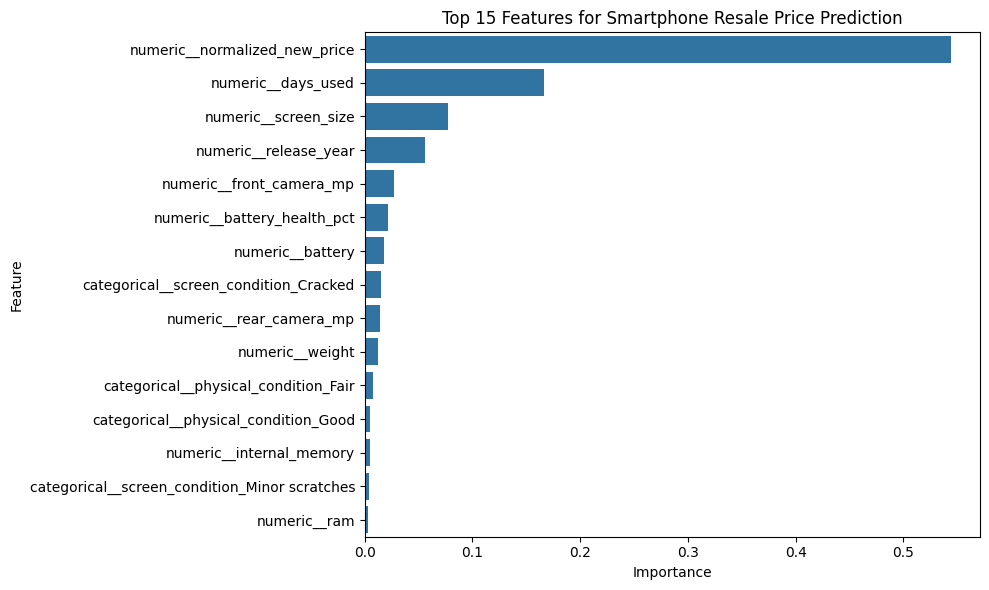

In [19]:

feature_names = (
    best_rf.named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = best_rf.named_steps["model"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df.head(15))

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)
plt.title("Top 15 Features for Smartphone Resale Price Prediction")
plt.tight_layout()
plt.show()


In [20]:
sample_phone = X_test.iloc[[0]]

predicted_price = best_rf.predict(sample_phone)[0]
actual_price = y_test.iloc[0]

print("ReCell Smartphone Value Estimator")
print("-" * 40)

print("\nSmartphone specifications:")
display(sample_phone.T.rename(columns={sample_phone.index[0]: "Value"}))

print(f"\nPredicted normalized resale price: {predicted_price:.4f}")
print(f"Actual normalized resale price:   {actual_price:.4f}")
print(f"Absolute prediction error:        {abs(predicted_price - actual_price):.4f}")


ReCell Smartphone Value Estimator
----------------------------------------

Smartphone specifications:


,Value
device_brand,Apple
os,iOS
screen_size,6.09
4g,yes
5g,yes
rear_camera_mp,47.4
front_camera_mp,12.5
internal_memory,1024.0
ram,8.0
battery,3633.0



Predicted normalized resale price: 5.4146
Actual normalized resale price:   5.6607
Absolute prediction error:        0.2461


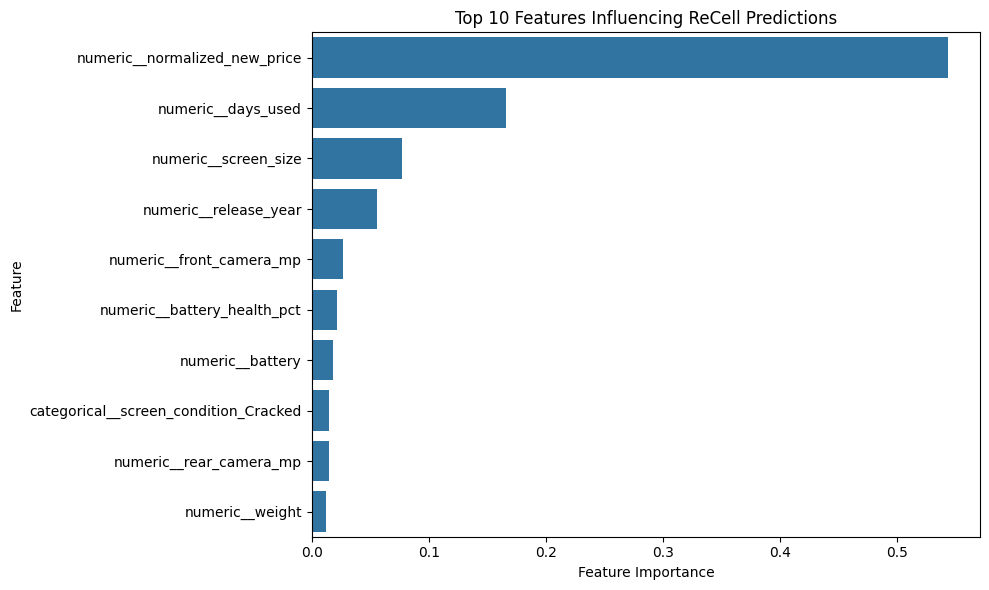

,Feature,Importance
9,numeric__normalized_new_price,0.5439
8,numeric__days_used,0.1665
0,numeric__screen_size,0.0769
7,numeric__release_year,0.0563
2,numeric__front_camera_mp,0.0267
10,numeric__battery_health_pct,0.0214
5,numeric__battery,0.0180
64,categorical__screen_condition_Cracked,0.0151
1,numeric__rear_camera_mp,0.0145
6,numeric__weight,0.0126


In [21]:

feature_names = best_rf.named_steps["preprocessor"].get_feature_names_out()
importances = best_rf.named_steps["model"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df.head(10),
    x="Importance",
    y="Feature"
)
plt.title("Top 10 Features Influencing ReCell Predictions")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

display(importance_df.head(10).round(4))


In [22]:

final_results = comparison[
    ["Model", "MAE", "RMSE", "R2 Score"]
].sort_values("RMSE").reset_index(drop=True)

display(final_results.round(4))

print("Best model:", final_results.loc[0, "Model"])
print("Best RMSE:", round(final_results.loc[0, "RMSE"], 4))
print("Best R²:", round(final_results.loc[0, "R2 Score"], 4))

,Model,MAE,RMSE,R2 Score
0,Tuned Random Forest,0.2283,0.2991,0.9048
1,Random Forest,0.2288,0.3011,0.9036
2,Decision Tree,0.2716,0.3720,0.8527
3,Linear Regression,0.3160,0.4227,0.8099
4,Ridge Regression,0.3160,0.4230,0.8096
5,Lasso Regression,0.3407,0.4731,0.7619


Best model: Tuned Random Forest
Best RMSE: 0.2991
Best R²: 0.9048
